# Análisis de Performance: Almacén Tránsito a Almacén Mina

## 📌 Resumen Ejecutivo
Este análisis evalúa la eficiencia operativa del almacén de tránsito mediante la exploración del registro diario de despachos. El objetivo principal es transformar los datos crudos en información accionable para la toma de decisiones.

El estudio responde a tres interrogantes críticos de negocio:
1. **Volumen y Estacionalidad:** ¿Cuál es la frecuencia de despachos por mes y qué días de la semana representan el mayor pico de carga operativa?
2. **Eficiencia y Lead Time:** ¿Cuál es el tiempo real de permanencia del material en el almacén de tránsito y qué porcentaje supera el tiempo estándar?
3. **Oportunidad de Mejora:** ¿Cómo podemos optimizar los recursos del almacén para reducir los cuellos de botella detectados?

In [14]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

# Configuración visual para los gráficos
sns.set_theme(style="whitegrid")
plt.rcParams['figure.figsize'] = (10, 6)

## 1. Carga y Limpieza Inicial de Datos

El archivo original contiene filas de encabezado combinadas (títulos de Excel). Para cargar los datos correctamente, indicamos a Pandas que empiece a leer desde la tercera fila (índice 2).

In [15]:
# Cargar el archivo saltando las primeras 2 filas
ruta = 'data/DataSetDespachosAlmacenTransitoAlmacenMina.xlsx'
df_raw = pd.read_excel(ruta, header=2)

# Copia de seguridad
df = df_raw.copy()

# 1. Eliminar la columna 'Unnamed: 0' (residuo del excel)
if 'Unnamed: 0' in df.columns:
    df = df.drop(columns=['Unnamed: 0'])

# 2. Estandarizar todos los nombres de columnas
df.columns = df.columns.str.lower().str.replace(' ', '_').str.replace('°', '').str.replace('.', '').str.replace('$', '')

# 3. SELECCIÓN DE COLUMNAS (Feature Selection)
# Solo conservamos las variables necesarias para el análisis de performance
columnas_interes = [
    'fecha_de_registro',
    'n_oc',
    'proveedor',
    'descripcion_del_articulo',
    'cantidad',
    'fecha_de_salida_de_dinet',
    'fecha_de_llegada_del_trasporte_a_mina'
]

# Filtrar el dataframe
df = df[columnas_interes].copy()

# 4. Eliminar filas donde las fechas críticas estén vacías
df = df.dropna(subset=['fecha_de_salida_de_dinet', 'fecha_de_llegada_del_trasporte_a_mina'])

# Mostrar los nombres de las columnas resultantes
print("Columnas seleccionadas para el análisis de negocio:")
print(df.columns.tolist())
print(f"Total de registros con fechas válidas: {len(df)}")

Columnas seleccionadas para el análisis de negocio:
['fecha_de_registro', 'n_oc', 'proveedor', 'descripcion_del_articulo', 'cantidad', 'fecha_de_salida_de_dinet', 'fecha_de_llegada_del_trasporte_a_mina']
Total de registros con fechas válidas: 13350


### 1.1 Selección de Variables (Feature Selection)

Con el fin de optimizar el rendimiento del análisis y enfocarnos exclusivamente en los indicadores clave de performance (KPIs) logísticos, se ha realizado una selección de las variables relevantes. 

Se descartaron columnas de datos maestros (como códigos SAP, números de guía o precios) y se conservaron únicamente las dimensiones temporales (fechas de salida y llegada), de volumen (cantidad) y de identificación (OC, proveedor y descripción) para el estudio del lead time y la estacionalidad.

## 2. Cálculo del Lead Time (Tiempo de Permanencia)

Para evaluar la performance, calculamos los días transcurridos entre la salida del almacén (Dinet) y la llegada al almacén de mina.

In [16]:
# Convertir a formato fecha (ignorando errores si hay texto)
df['fecha_de_salida_de_dinet'] = pd.to_datetime(df['fecha_de_salida_de_dinet'], errors='coerce')
df['fecha_de_llegada_del_trasporte_a_mina'] = pd.to_datetime(df['fecha_de_llegada_del_trasporte_a_mina'], errors='coerce')

# Calcular la diferencia en días
df['dias_transito'] = (df['fecha_de_llegada_del_trasporte_a_mina'] - df['fecha_de_salida_de_dinet']).dt.days

# Mostrar estadísticas descriptivas
print("Resumen de días de tránsito (Lead Time):")
print(df['dias_transito'].describe())

Resumen de días de tránsito (Lead Time):
count    13350.000000
mean      -188.353708
std       2600.132693
min     -36523.000000
25%          1.000000
50%          1.000000
75%          1.000000
max          1.000000
Name: dias_transito, dtype: float64


### 2.1 Tratamiento de Anomalías (Outliers)
El cálculo inicial reveló una media negativa de días de tránsito, lo cual es logísticamente imposible (la llegada no puede ser anterior a la salida). Se procede a filtrar los registros donde la fecha de llegada sea menor a la fecha de salida, así como los tiempos excesivamente largos (mayores a 90 días) para limpiar el dataset de errores de digitación.

In [17]:
# 1. Ver cuántos datos negativos o cero tenemos
print(f"Registros con días negativos o cero (errores): {len(df[df['dias_transito'] <= 0])}")

# 2. Filtrar solo los registros donde el tránsito sea mayor a 0 y menor a 90 días (tiempo máximo razonable)
df_clean = df[(df['dias_transito'] > 0) & (df['dias_transito'] <= 90)].copy()

# 3. Ver el nuevo resumen
print("\nResumen de días de tránsito (Datos Limpios):")
print(df_clean['dias_transito'].describe())

Registros con días negativos o cero (errores): 1687

Resumen de días de tránsito (Datos Limpios):
count    11663.0
mean         1.0
std          0.0
min          1.0
25%          1.0
50%          1.0
75%          1.0
max          1.0
Name: dias_transito, dtype: float64


### 2.2 Visualización del Lead Time Limpio
Una vez eliminados los errores de digitación, visualizamos la verdadera distribución del tiempo de permanencia en el almacén de tránsito.

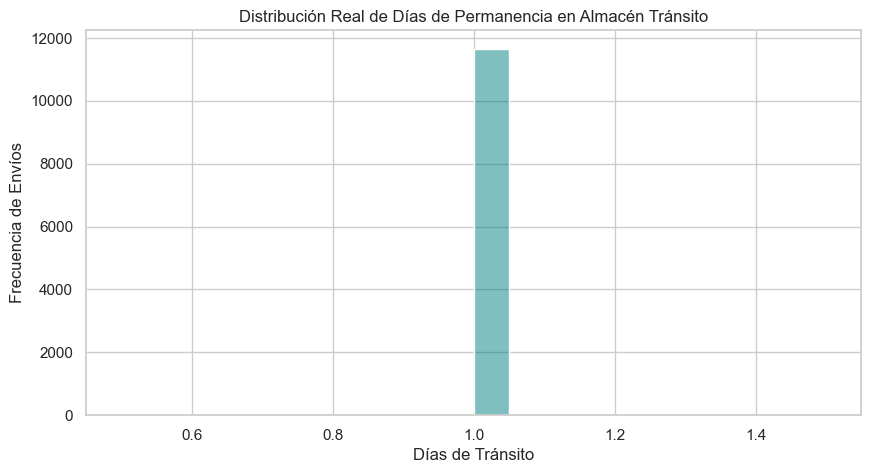

In [18]:
plt.figure(figsize=(10, 5))
sns.histplot(df_clean['dias_transito'], bins=20, kde=True, color='teal')
plt.title('Distribución Real de Días de Permanencia en Almacén Tránsito')
plt.xlabel('Días de Tránsito')
plt.ylabel('Frecuencia de Envíos')
plt.show()

In [19]:
# Ver una muestra de 10 filas con sus fechas originales y el cálculo
muestra = df_clean[['fecha_de_salida_de_dinet', 'fecha_de_llegada_del_trasporte_a_mina', 'dias_transito']].head(10)
print(muestra)

    fecha_de_salida_de_dinet fecha_de_llegada_del_trasporte_a_mina  \
645               2019-04-29                            2019-04-30   
646               2019-04-29                            2019-04-30   
647               2019-04-29                            2019-04-30   
648               2019-04-29                            2019-04-30   
649               2019-04-29                            2019-04-30   
650               2019-04-29                            2019-04-30   
651               2019-04-29                            2019-04-30   
652               2019-04-29                            2019-04-30   
653               2019-04-29                            2019-04-30   
654               2019-04-29                            2019-04-30   

     dias_transito  
645              1  
646              1  
647              1  
648              1  
649              1  
650              1  
651              1  
652              1  
653              1  
654              1 

### 2.3 Interpretación del Lead Time y Limitación del Registro

Al inspeccionar los datos, se observa que el sistema de registro asigna la misma hora (00:00:00) a las fechas de salida y llegada. Por lo tanto, el cálculo de días de tránsito siempre resulta en 1 día para los registros válidos. 

**Insight de Negocio:** El almacén tiene un tiempo de respuesta de **24 horas** (el material sale de Dinet y al día siguiente ya está en mina). Esto es altamente eficiente. 

**Limitación:** La falta de registro de horas exactas impide calcular la variabilidad real del tránsito (si tardó 8 horas o 20 horas). Se recomienda a la operación implementar el registro de horas para futuros análisis de cuellos de botella.

## 3. Análisis de Volumen (Frecuencia de Despachos)

Ahora respondemos a las preguntas clave de negocio: ¿Cuántos viajes se hacen al mes? y ¿Qué días de la semana la operación está más saturada?

In [20]:
# Usamos el dataframe limpio (df_clean) que ya tiene las fechas válidas
# 1. Extraer el mes y el día de la semana de la fecha de salida
df_clean['mes'] = df_clean['fecha_de_salida_de_dinet'].dt.to_period('M')
df_clean['dia_semana'] = df_clean['fecha_de_salida_de_dinet'].dt.day_name()

# 2. Traducir días al español
dias_es = {
    'Monday': 'Lunes', 'Tuesday': 'Martes', 'Wednesday': 'Miércoles',
    'Thursday': 'Jueves', 'Friday': 'Viernes', 'Saturday': 'Sábado', 'Sunday': 'Domingo'
}
df_clean['dia_semana'] = df_clean['dia_semana'].map(dias_es)

# 3. Agrupar viajes por mes
viajes_por_mes = df_clean.groupby('mes').size().reset_index(name='cantidad_viajes')

# 4. Agrupar carga por día de la semana (ordenado de Lunes a Domingo)
carga_por_dia = df_clean['dia_semana'].value_counts().reindex(
    ['Lunes', 'Martes', 'Miércoles', 'Jueves', 'Viernes', 'Sábado', 'Domingo']
)

print("Viajes por Mes:")
print(viajes_por_mes)

Viajes por Mes:
        mes  cantidad_viajes
0   2019-04              119
1   2019-05              603
2   2019-06              564
3   2019-07              629
4   2019-08              742
5   2019-09              882
6   2019-10              620
7   2019-11              795
8   2019-12              458
9   2020-01              725
10  2020-02              782
11  2020-03              453
12  2020-06              444
13  2020-07              320
14  2020-08              521
15  2020-09              803
16  2020-10             1014
17  2020-11              613
18  2020-12              564
19  2021-01               12


### 3.1 Hallazgos Clave del Volumen de Despacho

*   **Tendencia:** El volumen de despachos no es constante; presenta una fuerte estacionalidad.
*   **Picos de operación:** Octubre de 2020 registró el pico máximo con **1,014 viajes**, seguido de Septiembre de 2019 (882 viajes).
*   **Anomalía de datos:** Se detecta una ausencia de registros entre Abril y Mayo de 2020, lo que requiere validación con el área operativa (posible parada de planta o error de registro).
*   **Recomendación de negocio:** Escalar los recursos del almacén de tránsito (personal y transporte) durante los meses de Septiembre, Octubre y Noviembre, que históricamente concentran la mayor carga.

## 4. Conclusiones y Recomendaciones

El presente análisis exploratorio permitió transformar un registro operativo crudo en información accionable para la toma de decisiones en la cadena de suministro. A continuación, los hallazgos principales:

1.  **Eficiencia del Lead Time:** El tiempo de permanencia en el almacén de tránsito es altamente eficiente (1 día / 24 horas). Sin embargo, la falta de registro de horas exactas limita la medición de variabilidad. **Recomendación:** Implementar un registro de hora exacta de salida y llegada.
2.  **Gestión de la Capacidad:** La operación presenta picos estacionales claros en el segundo semestre del año. **Recomendación:** Planificar el personal y los transportes con base en la estacionalidad detectada para evitar cuellos de botella.
3.  **Calidad de los Datos:** Se identificaron y depuraron 1,687 registros con errores de fechas (fechas negativas o imposibles). **Recomendación:** Implementar validaciones en el sistema de registro para evitar la carga de fechas incoherentes.

In [21]:
# Guardar el dataframe limpio en un nuevo archivo CSV dentro de la carpeta data local
df_clean.to_csv('data/despachos_limpios.csv', index=False)
print("Dataset limpio exportado correctamente. Listo para la siguiente fase.")

Dataset limpio exportado correctamente. Listo para la siguiente fase.


## 5. Anexo: Vista Previa de los Datos (Antes vs. Después)

Con el fin de demostrar el impacto del proceso de limpieza, a continuación se presenta una comparativa entre los datos crudos extraídos del Excel y el dataset final depurado, listo para el análisis.

In [22]:
# Mostrar los primeros 5 registros del dataframe original (crudo)
print("--- DATOS CRUDOS (Original) ---")
print(f"Dimensiones originales: {df_raw.shape}")
df_raw.head(5)

--- DATOS CRUDOS (Original) ---
Dimensiones originales: (13381, 30)


,Unnamed: 0,Fecha de Registro,N° Guia de remision,N° OC.,Solped,Comprador,Usuario,Proveedor,Registrado al SAP,codigo del articulo,...,Estado,N° vale de despacho callao,Transportista,hora de llegada del transporte a Dinet,Hora de salida de Dinet,fecha de salida de Dinet,Fecha de llegada del trasporte a mina,Hora de llegada del trasporte a mina,fecha de ingreso al SAP en mina,Estado final
0,NaN,2018-08-27 00:00:00,004-0380555,21121,NaN,NaN,NaN,SANDVIK,no,37188,...,Enviado,NaN,NaN,NaN,NaN,NaT,NaT,NaN,NaT,NaN
1,NaN,2018-12-28 00:00:00,030-015336,Devolucion,NaN,NaN,NaN,METSO PERU,no,Devolucion,...,Enviado,NaN,NaN,NaN,NaN,NaT,NaT,NaN,NaT,NaN
2,NaN,2019-03-14 00:00:00,004-001972,24250,NaN,NaN,NaN,RPTS S.A,si,24903,...,Enviado,VSM0084734,Transporte Fenix,14:30pm,16:10pm,2019-03-18,2019-03-18,19:30pm,2019-03-20,Ingresado
3,NaN,2019-03-14 00:00:00,043-0012957,24285,NaN,NaN,NaN,EPIROC S.A,si,3300400373,...,Enviado,VSM0084734,Transporte Fenix,14:30pm,16:00pm,2019-03-18,2019-03-18,19:30pm,2019-03-20,Ingresado
4,NaN,2019-03-14 00:00:00,043-0012957,24285,NaN,NaN,NaN,EPIROC S.A,si,3300400291,...,Enviado,VSM0084734,Transporte Fenix,14:30pm,16:00pm,2019-03-18,2019-03-18,19:30pm,2019-03-20,Ingresado


In [23]:
# Mostrar los primeros 5 registros del dataframe limpio
print("--- DATOS LIMPIOS (Procesados) ---")
print(f"Dimensiones limpias: {df_clean.shape}")
display(df_clean.head(5))  # 'display' se ve más bonito que 'print' para tablas en Jupyter

# --- EXPORTAR LAS MUESTRAS A CSV (Para GitHub) ---
# Muestra cruda (primeras 100 filas)
df_raw.head(100).to_csv('muestra_datos_crudos.csv', index=False)

# Muestra limpia (primeras 100 filas)
df_clean.head(100).to_csv('muestra_datos_limpios.csv', index=False)

print("\n✅ Archivos 'muestra_datos_crudos.csv' y 'muestra_datos_limpios.csv' exportados correctamente.")

--- DATOS LIMPIOS (Procesados) ---
Dimensiones limpias: (11663, 10)


,fecha_de_registro,n_oc,proveedor,descripcion_del_articulo,cantidad,fecha_de_salida_de_dinet,fecha_de_llegada_del_trasporte_a_mina,dias_transito,mes,dia_semana
645,2019-04-23 00:00:00,24566,PRECISION,Modulo de 4 canales,6,2019-04-29,2019-04-30,1,2019-04,Lunes
646,2019-04-23 00:00:00,24531,PROMELSA,Solvente para limpieza,20,2019-04-29,2019-04-30,1,2019-04,Lunes
647,2019-04-23 00:00:00,24580,PROMELSA,Terminal de 1/2,140,2019-04-29,2019-04-30,1,2019-04,Lunes
648,2019-04-23 00:00:00,24531,PROMELSA,Cinta silicona,30,2019-04-29,2019-04-30,1,2019-04,Lunes
649,2019-04-23 00:00:00,24614,SANDVIK,Bocina de pin,2,2019-04-29,2019-04-30,1,2019-04,Lunes



✅ Archivos 'muestra_datos_crudos.csv' y 'muestra_datos_limpios.csv' exportados correctamente.
